# 04 — HOG + PCA | KNN RGB224

Đọc HOG đã lưu ở notebook 03, fit PCA chỉ trên train để giữ 95% phương sai; transform train/dev rồi L2. Giữ 20 cấu hình KNN như notebook trước. Chạy Run All; tắt kernel cũ để giải phóng RAM. PCA full có thể tốn thời gian và bộ nhớ. Chỉ dùng train/dev, không đọc ảnh hoặc trích lại HOG. Chạy lại cập nhật kết quả trong results_224/hog_pca.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import json
import pickle
import sys
import sklearn
from pathlib import Path
from itertools import product
from time import perf_counter
from sklearn.decomposition import PCA
from sklearn.preprocessing import normalize
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
from IPython.display import display

PROJECT_ROOT = Path(r"C:\CS231")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from src.evaluation.value_metrics import evaluate_classification

input_dir = PROJECT_ROOT / "src" / "KNN" / "results_224" / "hog"
output_dir = PROJECT_ROOT / "src" / "KNN" / "results_224" / "hog_pca"
output_dir.mkdir(parents=True, exist_ok=True)

## 1. Đọc HOG và nhãn

Đọc file before_l2: HOG vẫn có L2-Hys theo block nhưng chưa chuẩn hóa L2 toàn vector. Không dùng X_train.npy đã L2 làm đầu vào PCA. Giữ nguyên thứ tự manifest và nhãn.

In [2]:
X_train_hog_raw = np.load(input_dir / "X_train_hog_before_l2.npy")
X_dev_hog_raw = np.load(input_dir / "X_dev_hog_before_l2.npy")
y_train = np.load(input_dir / "y_train.npy")
y_dev = np.load(input_dir / "y_dev.npy")
train_manifest = pd.read_csv(input_dir / "train_manifest.csv")
dev_manifest = pd.read_csv(input_dir / "dev_manifest.csv")
source_config = json.loads((input_dir / "run_config.json").read_text(encoding="utf-8"))
original_dim = X_train_hog_raw.shape[1]
print("HOG train:", X_train_hog_raw.shape, y_train.shape)
print("HOG dev:", X_dev_hog_raw.shape, y_dev.shape)
print("Dtype:", X_train_hog_raw.dtype)

HOG train: (12494, 6084) (12494,)
HOG dev: (1564, 6084) (1564,)
Dtype: float32


## 2. Fit PCA trên train

PCA học hướng biến thiên từ train, không dùng nhãn. Giữ 95% phương sai không phải giữ 95% khả năng nhận diện. Số chiều còn lại do train quyết định. Dùng solver full, không whitening, không thêm StandardScaler.

In [3]:
PCA_VARIANCE = 0.95
pca = PCA(n_components=PCA_VARIANCE, svd_solver="full", whiten=False)
start = perf_counter()
pca.fit(X_train_hog_raw)
pca_fit_seconds = perf_counter() - start

print("Số chiều ban đầu:", original_dim)
print("Số chiều sau PCA:", pca.n_components_)
print("Phương sai giữ lại:", pca.explained_variance_ratio_.sum())
print("Thời gian fit PCA (giây):", pca_fit_seconds)

Số chiều ban đầu: 6084
Số chiều sau PCA: 1418
Phương sai giữ lại: 0.95005643
Thời gian fit PCA (giây): 116.86914340000294


## 3. Transform rồi chuẩn hóa L2

Dev chỉ transform bằng PCA của train, không fit lại. Sau phép chiếu, L2 từng vector để dùng cùng nhánh kết hợp sau này. Đánh giá cả pipeline PCA rồi L2. Tọa độ PCA có thể âm; vẫn dùng Euclidean.

In [4]:
start = perf_counter()
X_train_hog_pca = pca.transform(X_train_hog_raw)
X_train_hog_pca = normalize(X_train_hog_pca, norm="l2").astype(np.float32)
train_transform_seconds = perf_counter() - start
del X_train_hog_raw

start = perf_counter()
X_dev_hog_pca = pca.transform(X_dev_hog_raw)
X_dev_hog_pca = normalize(X_dev_hog_pca, norm="l2").astype(np.float32)
dev_transform_seconds = perf_counter() - start
del X_dev_hog_raw

np.save(output_dir / "X_train.npy", X_train_hog_pca)
np.save(output_dir / "X_dev.npy", X_dev_hog_pca)
np.save(output_dir / "y_train.npy", y_train)
np.save(output_dir / "y_dev.npy", y_dev)
train_manifest.to_csv(output_dir / "train_manifest.csv", index=False)
dev_manifest.to_csv(output_dir / "dev_manifest.csv", index=False)
with (output_dir / "pca.pkl").open("wb") as file:
    pickle.dump(pca, file)

print("Train sau PCA + L2:", X_train_hog_pca.shape)
print("Dev sau PCA + L2:", X_dev_hog_pca.shape)
print("Giá trị hữu hạn:", np.isfinite(X_train_hog_pca).all(), np.isfinite(X_dev_hog_pca).all())
print("L2 bằng 1:",
      np.allclose(np.linalg.norm(X_train_hog_pca, axis=1), 1.0, atol=1e-5),
      np.allclose(np.linalg.norm(X_dev_hog_pca, axis=1), 1.0, atol=1e-5))

Train sau PCA + L2: (12494, 1418)
Dev sau PCA + L2: (1564, 1418)
Giá trị hữu hạn: True True
L2 bằng 1: True True


## 4. Phương sai tích lũy

Đường biểu diễn phương sai trên train, không phải Accuracy hay F1. Mức cuối phải đạt ít nhất 95%.

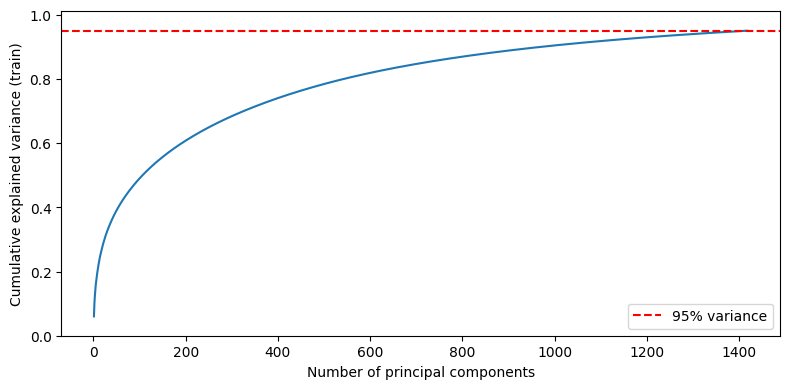

In [5]:
cumulative_variance = np.cumsum(pca.explained_variance_ratio_)
plt.figure(figsize=(8, 4))
plt.plot(np.arange(1, len(cumulative_variance) + 1), cumulative_variance)
plt.axhline(PCA_VARIANCE, color="red", linestyle="--", label="95% variance")
plt.xlabel("Number of principal components")
plt.ylabel("Cumulative explained variance (train)")
plt.ylim(0, 1.01)
plt.legend()
plt.tight_layout()
plt.savefig(output_dir / "pca_variance.png", dpi=150)
plt.show()
pd.DataFrame({
    "component": np.arange(1, len(cumulative_variance) + 1),
    "explained_variance_ratio": pca.explained_variance_ratio_,
    "cumulative_variance": cumulative_variance,
}).to_csv(output_dir / "pca_variance.csv", index=False)

## 5. Huấn luyện KNN — Grid Search riêng cho HOG

Giữ k=1..10 × uniform/distance × Euclidean = 20 cấu hình như notebook 02. Chọn Macro-F1 cao nhất, hòa thì MAE thấp hơn, vẫn hòa thì thứ tự thử. So sánh số chưa làm tròn.

In [6]:
grid_start = perf_counter()

n_neighbors_options = range(1, 11)
weight_options = ["uniform", "distance"]
metric_options = ["euclidean"]

results_hog_pca = []

for order, (k, weight, metric) in enumerate(
    product(n_neighbors_options, weight_options, metric_options)
):
    knn = KNeighborsClassifier(
        n_neighbors=k,
        weights=weight,
        metric=metric,
        algorithm="brute"
    )
    knn.fit(X_train_hog_pca, y_train)
    y_pred = knn.predict(X_dev_hog_pca)
    scores = evaluate_classification(y_dev, y_pred)

    results_hog_pca.append({
        "k": k,
        "weights": weight,
        "metric": metric,
        "macro_f1": scores["macro_f1"],
        "mae_vnd": scores["mae_vnd"],
        "accuracy": scores["accuracy"],
        "_order": order,
    })

df_results_hog_pca = (
    pd.DataFrame(results_hog_pca)
    .sort_values(
        ["macro_f1", "mae_vnd", "_order"],
        ascending=[False, True, True]
    )
    .drop(columns="_order")
    .reset_index(drop=True)
)

print("Tổng số cấu hình:", len(df_results_hog_pca))
display(df_results_hog_pca.head(10))

grid_seconds = perf_counter() - grid_start

Tổng số cấu hình: 20


,k,weights,metric,macro_f1,mae_vnd,accuracy
0,5,distance,euclidean,0.437934,106898.976982,0.443734
1,1,uniform,euclidean,0.431541,110249.360614,0.434783
2,1,distance,euclidean,0.431541,110249.360614,0.434783
3,2,distance,euclidean,0.431541,110249.360614,0.434783
4,6,distance,euclidean,0.431065,109801.790281,0.437340
5,3,distance,euclidean,0.430909,111061.381074,0.434783
6,8,distance,euclidean,0.429628,112838.874680,0.435422
7,7,distance,euclidean,0.429263,111125.319693,0.436701
8,4,distance,euclidean,0.428649,108753.196931,0.434143
9,5,uniform,euclidean,0.416595,105249.360614,0.423274


In [7]:
# Chọn cấu hình tốt nhất và so sánh các khoảng cách
best_hog_pca = df_results_hog_pca.iloc[0]
print("Cấu hình HOG tốt nhất trên DEV:")
print(best_hog_pca.to_string())

best_by_metric_hog_pca = (
    df_results_hog_pca
    .drop_duplicates(subset="metric", keep="first")
    .sort_values("macro_f1", ascending=False, kind="stable")
)

display(best_by_metric_hog_pca[
    ["metric", "k", "weights", "macro_f1", "mae_vnd", "accuracy"]
])

Cấu hình HOG tốt nhất trên DEV:
k                       5
weights          distance
metric          euclidean
macro_f1         0.437934
mae_vnd     106898.976982
accuracy         0.443734


,metric,k,weights,macro_f1,mae_vnd,accuracy
0,euclidean,5,distance,0.437934,106898.976982,0.443734


## 6. Confusion matrix của cấu hình HOG tốt nhất trên dev

In [8]:
# Đọc trực tiếp tham số từ Grid Search (không hard-code như ví dụ RGB cũ)
best_knn_hog_pca = KNeighborsClassifier(
    n_neighbors=int(best_hog_pca["k"]),
    weights=str(best_hog_pca["weights"]),
    metric=str(best_hog_pca["metric"]),
    algorithm="brute"
)
best_knn_hog_pca.fit(X_train_hog_pca, y_train)
start = perf_counter()
y_dev_pred_hog_pca = best_knn_hog_pca.predict(X_dev_hog_pca)
best_predict_seconds = perf_counter() - start

hog_pca_scores = evaluate_classification(y_dev, y_dev_pred_hog_pca)
print("DEV Accuracy:", hog_pca_scores["accuracy"])
print("DEV Macro-F1:", hog_pca_scores["macro_f1"])
print("DEV MAE_VND:", hog_pca_scores["mae_vnd"])


DEV Accuracy: 0.4437340153452685
DEV Macro-F1: 0.4379339420802933
DEV MAE_VND: 106898.97698209719


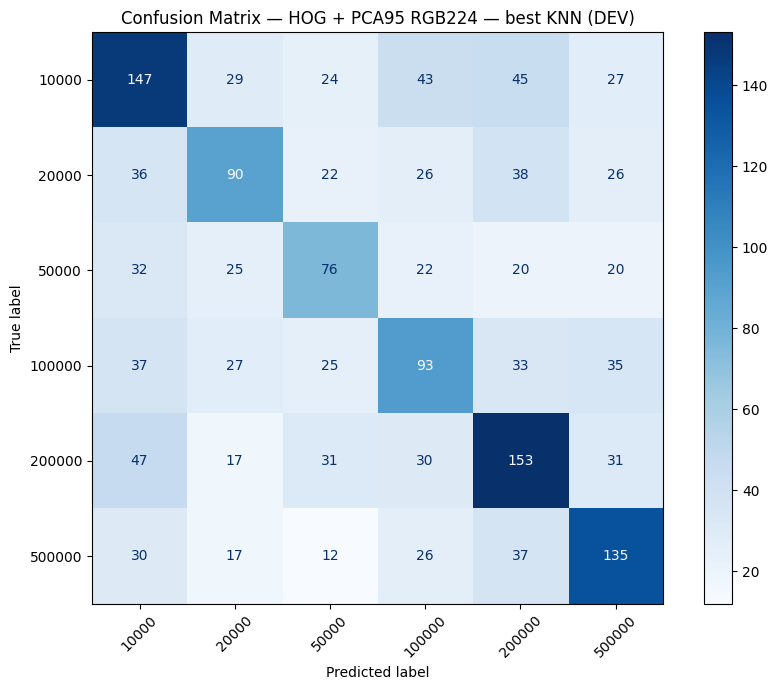

In [9]:
labels = np.sort(np.unique(y_train))
cm_hog_pca = confusion_matrix(y_dev, y_dev_pred_hog_pca, labels=labels)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_hog_pca,
    display_labels=labels
)
fig, ax = plt.subplots(figsize=(9, 7))
disp.plot(ax=ax, cmap="Blues", values_format="d", xticks_rotation=45)
ax.set_title("Confusion Matrix — HOG + PCA95 RGB224 — best KNN (DEV)")
plt.tight_layout()
plt.savefig(output_dir / "hog_pca_confusion_matrix_dev.png", dpi=150)
plt.show()

In [10]:
# Precision / Recall / F1 theo mệnh giá — đọc được lớp nào mạnh/yếu
report_hog_pca = classification_report(
    y_dev, y_dev_pred_hog_pca,
    labels=labels,
    output_dict=True,
    zero_division=0
)

per_class_hog_pca = pd.DataFrame([
    {
        "denomination_vnd": int(label),
        "precision": report_hog_pca[str(label)]["precision"],
        "recall": report_hog_pca[str(label)]["recall"],
        "f1": report_hog_pca[str(label)]["f1-score"],
        "support": int(report_hog_pca[str(label)]["support"]),
    }
    for label in labels
])
display(per_class_hog_pca)

print(f"Số ảnh đúng: {np.trace(cm_hog_pca)}/{cm_hog_pca.sum()}")

,denomination_vnd,precision,recall,f1,support
0,10000,0.446809,0.466667,0.456522,315
1,20000,0.439024,0.378151,0.406321,238
2,50000,0.400000,0.389744,0.394805,195
3,100000,0.387500,0.372000,0.379592,250
4,200000,0.469325,0.495146,0.481890,309
5,500000,0.492701,0.525292,0.508475,257


Số ảnh đúng: 694/1564


In [11]:
# Những cặp mệnh giá có tổng số nhầm lẫn hai chiều lớn nhất
error_pairs_hog_pca = []
for i in range(len(labels)):
    for j in range(i + 1, len(labels)):
        errors_ij = int(cm_hog_pca[i, j])
        errors_ji = int(cm_hog_pca[j, i])
        error_pairs_hog_pca.append({
            "pair": f"{labels[i]} ↔ {labels[j]}",
            "true_i_pred_j": errors_ij,
            "true_j_pred_i": errors_ji,
            "total_errors": errors_ij + errors_ji,
        })

df_error_pairs_hog_pca = (
    pd.DataFrame(error_pairs_hog_pca)
    .sort_values("total_errors", ascending=False, kind="stable")
)
print("Top 5 cặp mệnh giá nhầm lẫn nhiều nhất:")
display(df_error_pairs_hog_pca.head(5))

Top 5 cặp mệnh giá nhầm lẫn nhiều nhất:


,pair,true_i_pred_j,true_j_pred_i,total_errors
3,10000 ↔ 200000,45,47,92
2,10000 ↔ 100000,43,37,80
14,200000 ↔ 500000,31,37,68
0,10000 ↔ 20000,29,36,65
12,100000 ↔ 200000,33,30,63


## Lưu kết quả HOG + PCA

Feature, nhãn, manifest và PCA đã lưu ở bước 3. Bước kết hợp dùng nguyên các đầu ra này. File pca.pkl chỉ nạp từ nguồn tin cậy do nhóm tạo và môi trường thư viện tương thích.

In [12]:
output_dir = PROJECT_ROOT / "src" / "KNN" / "results_224" / "hog_pca"
output_dir.mkdir(parents=True, exist_ok=True)

summary_hog_pca = pd.DataFrame([{
    "feature": "HOG RGB224 + PCA95 + L2",
    "feature_dim": X_train_hog_pca.shape[1],
    "k": int(best_hog_pca["k"]),
    "weights": str(best_hog_pca["weights"]),
    "metric": str(best_hog_pca["metric"]),
    "macro_f1": float(best_hog_pca["macro_f1"]),
    "mae_vnd": float(best_hog_pca["mae_vnd"]),
    "accuracy": float(best_hog_pca["accuracy"]),
}])

df_results_hog_pca.to_csv(output_dir / "hog_pca_knn_grid_dev.csv", index=False)
summary_hog_pca.to_csv(output_dir / "hog_pca_best_dev.csv", index=False)
pd.DataFrame(cm_hog_pca, index=labels, columns=labels).to_csv(
    output_dir / "hog_pca_confusion_matrix_dev.csv"
)
per_class_hog_pca.to_csv(output_dir / "hog_pca_per_class_dev.csv", index=False)

print("Đã lưu vào:", output_dir.resolve())
display(summary_hog_pca)

predictions = dev_manifest[["relative_path"]].copy()
predictions["y_true_vnd"] = y_dev
predictions["y_pred_vnd"] = y_dev_pred_hog_pca
predictions.to_csv(output_dir / "predictions_dev.csv", index=False)
(output_dir / "metrics_dev.json").write_text(json.dumps(hog_pca_scores, indent=2), encoding="utf-8")

config = {
    "source_hog_config": source_config,
    "pca": True, "pca_fit_split": "train",
    "pca_variance_requested": PCA_VARIANCE, "pca_solver": "full", "whiten": False,
    "original_dim": original_dim, "pca_dim": int(pca.n_components_),
    "explained_variance_ratio_sum": float(pca.explained_variance_ratio_.sum()),
    "whole_vector_norm_after_pca": "L2", "feature_dtype": "float32",
    "k_options": list(n_neighbors_options), "weight_options": weight_options,
    "metric_options": metric_options, "algorithm": "brute",
    "best_k": int(best_hog_pca["k"]), "best_weights": str(best_hog_pca["weights"]),
    "best_metric": str(best_hog_pca["metric"]),
    "timing_seconds": {
        "pca_fit": pca_fit_seconds,
        "train_transform_and_l2": train_transform_seconds,
        "dev_transform_and_l2": dev_transform_seconds,
        "grid_fit_predict_and_metrics": grid_seconds,
        "best_dev_predict_only": best_predict_seconds,
    },
    "versions": {"sklearn": sklearn.__version__, "numpy": np.__version__},
}
(output_dir / "run_config.json").write_text(json.dumps(config, indent=2), encoding="utf-8")

Đã lưu vào: C:\CS231\src\KNN\results_224\hog_pca


,feature,feature_dim,k,weights,metric,macro_f1,mae_vnd,accuracy
0,HOG RGB224 + PCA95 + L2,1418,5,distance,euclidean,0.437934,106898.976982,0.443734


1591

## 7. Đối chiếu HOG không PCA

Bảng đầu dùng cấu hình tốt nhất mỗi nhánh. Bảng sau cố định k=1, uniform, Euclidean. Đánh giá kết quả PCA+L2, không chỉ riêng số chiều. HOG trước chưa đo thời gian cùng cách nên chưa kết luận tăng tốc bao nhiêu lần.

In [13]:
baseline = pd.read_csv(input_dir / "hog_best_dev.csv")
comparison = pd.concat([baseline, summary_hog_pca], ignore_index=True)
comparison.to_csv(output_dir / "comparison_best_dev.csv", index=False)
display(comparison[["feature", "feature_dim", "k", "weights", "accuracy", "macro_f1", "mae_vnd"]])

baseline_grid = pd.read_csv(input_dir / "hog_knn_grid_dev.csv")
reference_rows = []
for name, grid in [("HOG", baseline_grid), ("HOG + PCA95 + L2", df_results_hog_pca)]:
    row = grid.loc[(grid["k"] == 1) & (grid["weights"] == "uniform")].iloc[0].to_dict()
    row["feature"] = name
    reference_rows.append(row)
reference_comparison = pd.DataFrame(reference_rows)
reference_comparison.to_csv(output_dir / "comparison_reference_dev.csv", index=False)
display(reference_comparison[["feature", "k", "weights", "metric", "accuracy", "macro_f1", "mae_vnd"]])

,feature,feature_dim,k,weights,accuracy,macro_f1,mae_vnd
0,HOG RGB224 - no PCA,6084,1,uniform,0.390665,0.390748,116234.015345
1,HOG RGB224 + PCA95 + L2,1418,5,distance,0.443734,0.437934,106898.976982


,feature,k,weights,metric,accuracy,macro_f1,mae_vnd
0,HOG,1,uniform,euclidean,0.390665,0.390748,116234.015345
1,HOG + PCA95 + L2,1,uniform,euclidean,0.434783,0.431541,110249.360614


Sau khi chạy, ghi số chiều còn lại, phương sai và điểm dev. Giữ cả HOG gốc và HOG-PCA cho hai biến thể kết hợp HSV12, không loại một nhánh theo kết quả ở đây. Chưa đánh giá test.